##data and captions

Using device: cuda


100%|██████████| 26.4M/26.4M [00:02<00:00, 12.0MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 205kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.80MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 11.0MB/s]


Train images: 60000 | Test images: 10000
Text vocab size: 20 | Max caption length: 6


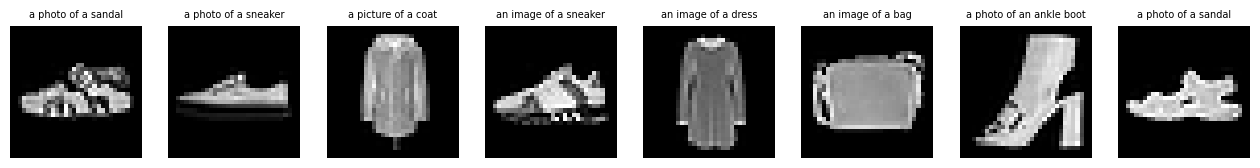

In [ ]:
import random
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

# Images: Fashion MNIST is 28x28.
#Padding by 2 pixels on each side to get 32x32,
# because 32 divides cleanly into the 8x8 token grid used in Section 2.
transform = transforms.Compose([transforms.Pad(2), transforms.ToTensor()])
train_base = datasets.FashionMNIST("data", train=True, download=True, transform=transform)
test_base = datasets.FashionMNIST("data", train=False, download=True, transform=transform)

# Captions: the dataset only has class labels, so the captions are from templates.
CLASS_PHRASES = ["a tshirt", "a trouser", "a pullover", "a dress", "a coat",
                 "a sandal", "a shirt", "a sneaker", "a bag", "an ankle boot"]
TEMPLATES = ["a photo of {}", "an image of {}", "a picture of {}", "this is {}"]

# Text tokenizer: every distinct word gets an integer id. Id 0 is padding.
all_captions = [t.format(c) for t in TEMPLATES for c in CLASS_PHRASES]
vocab = ["<pad>"] + sorted({w for cap in all_captions for w in cap.split()})
word2id = {w: i for i, w in enumerate(vocab)}
MAX_TEXT_LEN = max(len(cap.split()) for cap in all_captions)
TEXT_VOCAB_SIZE = len(vocab)

def encode_caption(text):
    ids = [word2id[w] for w in text.split()]
    ids += [0] * (MAX_TEXT_LEN - len(ids))
    return torch.tensor(ids)

class CaptionedFashionMNIST(Dataset):
    """Returns (image, caption token ids, class label). Caption template is random each time."""
    def __init__(self, base):
        self.base = base
    def __len__(self):
        return len(self.base)
    def __getitem__(self, i):
        img, label = self.base[i]
        caption = random.choice(TEMPLATES).format(CLASS_PHRASES[label])
        return img, encode_caption(caption), label

train_ds = CaptionedFashionMNIST(train_base)
test_ds = CaptionedFashionMNIST(test_base)
train_loader = DataLoader(train_ds, batch_size=128, shuffle=True, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=128, shuffle=False, num_workers=0)

print("Train images:", len(train_ds), "| Test images:", len(test_ds))
print("Text vocab size:", TEXT_VOCAB_SIZE, "| Max caption length:", MAX_TEXT_LEN)

# Look at a few samples with their captions
imgs, caps, labels = next(iter(train_loader))
fig, axes = plt.subplots(1, 8, figsize=(16, 2.4))
for ax, im, cp in zip(axes, imgs, caps):
    ax.imshow(im[0], cmap="gray"); ax.axis("off")
    ax.set_title(" ".join(vocab[t] for t in cp if t != 0), fontsize=7)
plt.show()

##image tokenizer

In [ ]:
import math
import torch.nn as nn
import torch.nn.functional as F

NUM_CODES = 128 # size of the image-vocabulary
GRID = 8  # each image becomes an 8x8 grid of tokens
IMG_SEQ_LEN = GRID * GRID # 64 image tokens per image

class DVAE(nn.Module):
    def __init__(self, num_codes=NUM_CODES, hidden=64):
        super().__init__()
        # Encoder: 32x32 image -> 8x8 grid, with a score for each of the K codes in every cell
        self.encoder = nn.Sequential(
            nn.Conv2d(1, hidden, 4, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(hidden, hidden, 4, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(hidden, hidden, 3, padding=1), nn.ReLU(),
            nn.Conv2d(hidden, num_codes, 1))
        # Codebook: one learnable vector per code
        self.codebook = nn.Embedding(num_codes, hidden)
        # Decoder: 8x8 grid of code vectors -> 32x32 image
        self.decoder = nn.Sequential(
            nn.Conv2d(hidden, hidden, 3, padding=1), nn.ReLU(),
            nn.ConvTranspose2d(hidden, hidden, 4, stride=2, padding=1), nn.ReLU(),
            nn.ConvTranspose2d(hidden, 1, 4, stride=2, padding=1), nn.Sigmoid())

    def forward(self, x, temperature):
        logits = self.encoder(x) # (B, K, 8, 8)
        soft = F.gumbel_softmax(logits, tau=temperature, dim=1) # soft choice of a code per cell
        z = torch.einsum("bkhw,kd->bdhw", soft, self.codebook.weight)
        return self.decoder(z), logits

    @torch.no_grad()
    def get_tokens(self, x): # image -> 64 integers
        return self.encoder(x).argmax(dim=1).flatten(1)

    @torch.no_grad()
    def decode_tokens(self, tokens): # 64 integers -> image
        B = tokens.shape[0]
        z = self.codebook(tokens).view(B, GRID, GRID, -1).permute(0, 3, 1, 2)
        return self.decoder(z)

print("Parameters:", sum(p.numel() for p in DVAE().parameters()))

Parameters: 223681


##training tokenizer

dVAE epoch 1/10  reconstruction MSE: 0.02220
dVAE epoch 2/10  reconstruction MSE: 0.00782
dVAE epoch 3/10  reconstruction MSE: 0.00643
dVAE epoch 4/10  reconstruction MSE: 0.00577
dVAE epoch 5/10  reconstruction MSE: 0.00540
dVAE epoch 6/10  reconstruction MSE: 0.00519
dVAE epoch 7/10  reconstruction MSE: 0.00505
dVAE epoch 8/10  reconstruction MSE: 0.00495
dVAE epoch 9/10  reconstruction MSE: 0.00489
dVAE epoch 10/10  reconstruction MSE: 0.00494
Test MSE: 0.005458833649754524
Codes used (out of 128 ): 43


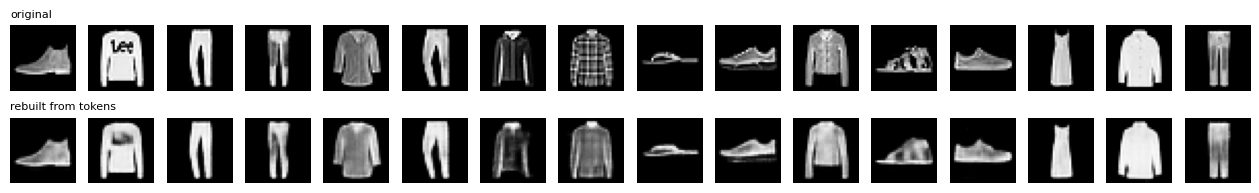

In [ ]:
dvae = DVAE().to(device)
opt_d = torch.optim.Adam(dvae.parameters(), lr=0.001)
EPOCHS_DVAE = 10
TEMP_START, TEMP_END = 1.0, 0.1 # temperature falls, so choices become closer to hard picks
KL_WEIGHT = 0.0005 # gentle push to use many different codes
total_steps = EPOCHS_DVAE * len(train_loader)
step = 0

for epoch in range(EPOCHS_DVAE):
    dvae.train()
    running = 0.0
    for imgs, _, _ in train_loader:
        imgs = imgs.to(device)
        temp = TEMP_START + (TEMP_END - TEMP_START) * step / total_steps
        recon, logits = dvae(imgs, temp)
        recon_loss = F.mse_loss(recon, imgs)
        log_q = F.log_softmax(logits, dim=1)
        kl = (log_q.exp() * (log_q + math.log(NUM_CODES))).sum(dim=1).mean()
        loss = recon_loss + KL_WEIGHT * kl
        opt_d.zero_grad(); loss.backward(); opt_d.step()
        running += recon_loss.item(); step += 1
    print(f"dVAE epoch {epoch + 1}/{EPOCHS_DVAE}  reconstruction MSE: {running / len(train_loader):.5f}")

# Check: encode real test images into tokens, decode them back, compare
dvae.eval()
test_imgs = torch.stack([test_base[i][0] for i in range(16)]).to(device)
tokens = dvae.get_tokens(test_imgs)
recon = dvae.decode_tokens(tokens)
print("Test MSE:", F.mse_loss(recon, test_imgs).item())
print("Codes used (out of", NUM_CODES, "):", tokens.unique().numel())

fig, axes = plt.subplots(2, 16, figsize=(16, 2.2))
for i in range(16):
    axes[0, i].imshow(test_imgs[i, 0].cpu(), cmap="gray"); axes[0, i].axis("off")
    axes[1, i].imshow(recon[i, 0].cpu(), cmap="gray"); axes[1, i].axis("off")
axes[0, 0].set_title("original", fontsize=8, loc="left")
axes[1, 0].set_title("rebuilt from tokens", fontsize=8, loc="left")
plt.show()

##transformer

In [ ]:
class MiniDALLE(nn.Module):
    def __init__(self, dim=256, depth=4, heads=4, dropout=0.1):
        super().__init__()
        self.total_vocab = TEXT_VOCAB_SIZE + NUM_CODES # text words and image codes share one vocabulary
        self.seq_len = MAX_TEXT_LEN + IMG_SEQ_LEN
        self.tok_emb = nn.Embedding(self.total_vocab, dim)
        self.pos_emb = nn.Embedding(self.seq_len, dim)
        layer = nn.TransformerEncoderLayer(dim, heads, dim * 4, dropout,
                                           batch_first=True, norm_first=True, activation="gelu")
        self.blocks = nn.TransformerEncoder(layer, depth, enable_nested_tensor=False)
        self.norm = nn.LayerNorm(dim)
        self.head = nn.Linear(dim, self.total_vocab)

    def forward(self, seq):
        B, L = seq.shape
        x = self.tok_emb(seq) + self.pos_emb(torch.arange(L, device=seq.device))
        causal = torch.triu(torch.ones(L, L, device=seq.device, dtype=torch.bool), diagonal=1)
        x = self.blocks(x, mask=causal) # each position sees only earlier positions
        return self.head(self.norm(x))

@torch.no_grad()
def tokenize_dataset(base):
    dvae.eval()
    toks, labs = [], []
    for imgs, labels in DataLoader(base, batch_size=256, shuffle=False):
        toks.append(dvae.get_tokens(imgs.to(device)).cpu())
        labs.append(labels)
    return torch.cat(toks), torch.cat(labs)

train_img_tokens, train_labels = tokenize_dataset(train_base)
print("Token table:", train_img_tokens.shape) # (60000, 64)

def make_batch(indices):
    caps = torch.stack([encode_caption(random.choice(TEMPLATES).format(CLASS_PHRASES[int(train_labels[i])]))
                        for i in indices.tolist()])
    img_part = train_img_tokens[indices] + TEXT_VOCAB_SIZE # shift image codes after the text words
    return torch.cat([caps, img_part], dim=1) # [caption tokens][image tokens]

model = MiniDALLE().to(device)
print("Transformer parameters:", sum(p.numel() for p in model.parameters()))

Token table: torch.Size([60000, 64])
Transformer parameters: 3253396


##training transformer

In [ ]:
EPOCHS_TF = 15
BATCH = 128
opt_t = torch.optim.AdamW(model.parameters(), lr=0.0003, weight_decay=0.01)

# Image tokens count 7 times more than caption tokens, as in the original DALL-E
weights = torch.cat([torch.full((MAX_TEXT_LEN - 1,), 1.0),
                     torch.full((IMG_SEQ_LEN,), 7.0)]).to(device)

N = len(train_img_tokens)
for epoch in range(EPOCHS_TF):
    model.train()
    perm = torch.randperm(N)
    running, count = 0.0, 0
    for i in range(0, N, BATCH):
        seq = make_batch(perm[i:i + BATCH]).to(device)
        logits = model(seq[:, :-1])
        per_token = F.cross_entropy(logits.reshape(-1, model.total_vocab),
                                    seq[:, 1:].reshape(-1), reduction="none").view(seq.size(0), -1)
        loss = (per_token * weights).sum() / (weights.sum() * seq.size(0))
        opt_t.zero_grad(); loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt_t.step()
        running += loss.item(); count += 1
    print(f"Transformer epoch {epoch + 1}/{EPOCHS_TF}  loss: {running / count:.4f}")

Transformer epoch 1/15  loss: 2.1039
Transformer epoch 2/15  loss: 1.6570
Transformer epoch 3/15  loss: 1.5714
Transformer epoch 4/15  loss: 1.5238
Transformer epoch 5/15  loss: 1.4909
Transformer epoch 6/15  loss: 1.4666
Transformer epoch 7/15  loss: 1.4467
Transformer epoch 8/15  loss: 1.4309
Transformer epoch 9/15  loss: 1.4170
Transformer epoch 10/15  loss: 1.4049
Transformer epoch 11/15  loss: 1.3940
Transformer epoch 12/15  loss: 1.3850
Transformer epoch 13/15  loss: 1.3758
Transformer epoch 14/15  loss: 1.3680
Transformer epoch 15/15  loss: 1.3614


##generating and evaluating images

Classifier on real images:          0.892
Classifier on dVAE reconstructions: 0.865  (the ceiling for generation)
      a tshirt: caption match 0.82
     a trouser: caption match 1.00
    a pullover: caption match 0.71
       a dress: caption match 0.84
        a coat: caption match 0.89
      a sandal: caption match 0.90
       a shirt: caption match 0.56
     a sneaker: caption match 0.98
         a bag: caption match 0.97
 an ankle boot: caption match 0.96
Overall caption match: 0.863


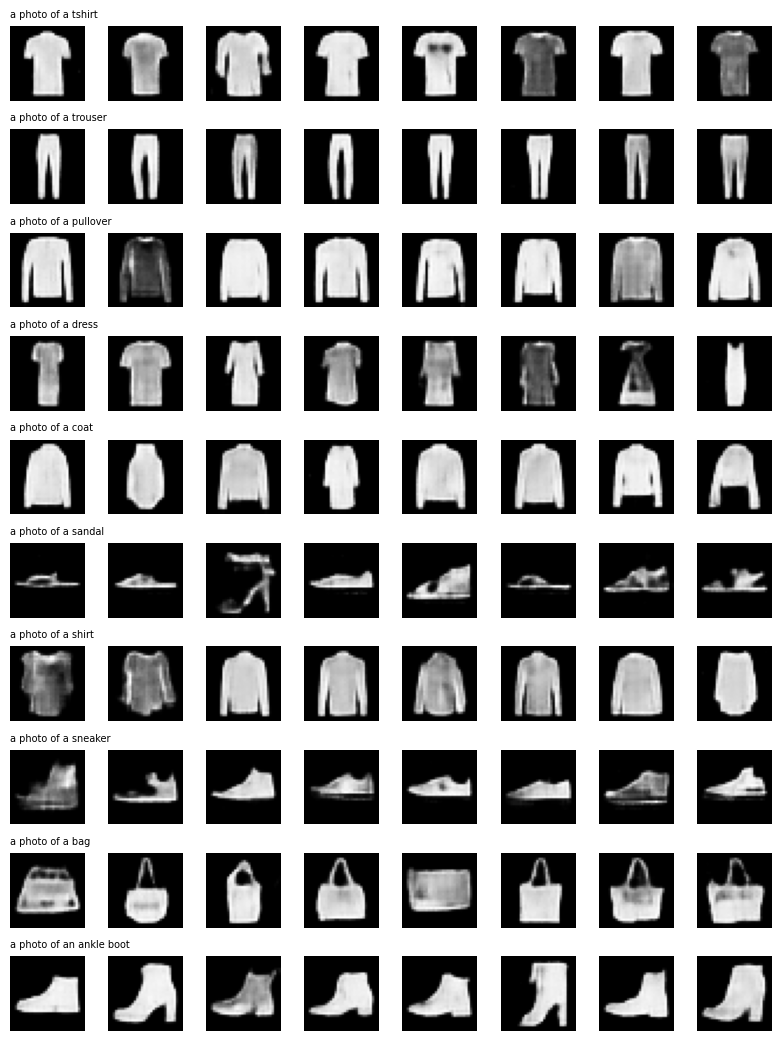

In [ ]:
@torch.no_grad()
def generate(captions, temperature=1.0, top_k=20):
    model.eval()
    seq = torch.stack([encode_caption(c) for c in captions]).to(device)
    for _ in range(IMG_SEQ_LEN): # one image token at a time
        logits = model(seq)[:, -1, TEXT_VOCAB_SIZE:] / temperature # only image codes allowed
        kth = torch.topk(logits, top_k).values[:, -1:]
        logits = logits.masked_fill(logits < kth, torch.finfo(logits.dtype).min)
        nxt = torch.multinomial(F.softmax(logits, dim=-1), 1) + TEXT_VOCAB_SIZE
        seq = torch.cat([seq, nxt], dim=1)
    return dvae.decode_tokens(seq[:, MAX_TEXT_LEN:] - TEXT_VOCAB_SIZE)

# A small CNN classifier trained on real images acts as the judge
clf = nn.Sequential(nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                    nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
                    nn.Flatten(), nn.Linear(64 * 8 * 8, 128), nn.ReLU(), nn.Linear(128, 10)).to(device)
opt_c = torch.optim.Adam(clf.parameters(), lr=0.001)
for epoch in range(3):
    for imgs, labels in DataLoader(train_base, batch_size=256, shuffle=True):
        loss = F.cross_entropy(clf(imgs.to(device)), labels.to(device))
        opt_c.zero_grad(); loss.backward(); opt_c.step()
clf.eval()

with torch.no_grad():
    real = torch.stack([test_base[i][0] for i in range(2000)]).to(device)
    real_lab = torch.tensor([test_base[i][1] for i in range(2000)]).to(device)
    acc_real = (clf(real).argmax(1) == real_lab).float().mean().item()
    acc_recon = (clf(dvae.decode_tokens(dvae.get_tokens(real))).argmax(1) == real_lab).float().mean().item()
print(f"Classifier on real images:          {acc_real:.3f}")
print(f"Classifier on dVAE reconstructions: {acc_recon:.3f}  (the ceiling for generation)")

# Generate 100 images per caption and check whether the classifier agrees with the caption
accs = []
for c in range(10):
    imgs = generate([f"a photo of {CLASS_PHRASES[c]}"] * 100)
    with torch.no_grad():
        accs.append((clf(imgs).argmax(1) == c).float().mean().item())
    print(f"{CLASS_PHRASES[c]:>14}: caption match {accs[-1]:.2f}")
print(f"Overall caption match: {sum(accs) / len(accs):.3f}")

# Picture grid: one row per caption
fig, axes = plt.subplots(10, 8, figsize=(8, 10.5))
for c in range(10):
    imgs = generate([f"a photo of {CLASS_PHRASES[c]}"] * 8)
    for j in range(8):
        axes[c, j].imshow(imgs[j, 0].cpu(), cmap="gray"); axes[c, j].axis("off")
    axes[c, 0].set_title(f"a photo of {CLASS_PHRASES[c]}", fontsize=7, loc="left")
plt.tight_layout(); plt.show()

##saving trained models to colab

In [ ]:
from google.colab import drive
import os
drive.mount('/content/drive')
SAVE_DIR = "/content/drive/MyDrive/dalle_fashion"
os.makedirs(SAVE_DIR, exist_ok=True)
torch.save(dvae.state_dict(), f"{SAVE_DIR}/dvae.pt")
torch.save(model.state_dict(), f"{SAVE_DIR}/transformer.pt")
torch.save(clf.state_dict(), f"{SAVE_DIR}/classifier.pt")
print("Saved to", SAVE_DIR)

Mounted at /content/drive
Saved to /content/drive/MyDrive/dalle_fashion
